# 02 · EDA textual e preparação do texto

O notebook 01 decidiu o grão e os metadados. Este olha para o texto que vai ser indexado: quanto dele sobra depois da limpeza, se os documentos cabem inteiros no modelo de embeddings, o que se repete, que palavras separam clientes satisfeitos de insatisfeitos e o que isso implica para a recuperação.

O pré-processamento está em `src/preprocessing/` e gera `data/processed/documentos.parquet` (`make documentos`), com o texto em três versões: original para exibição, limpo para os embeddings e o contexto do LLM, normalizado para a deduplicação e o índice lexical.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.preprocessing.limpeza import normalize
from src.preprocessing.tokenizacao import stopwords
from src.visualization.estilo import BLUE, GRAY, GREEN, ORANGE, RED, SCORE_COLORS, apply_style, fmt_pct, save

apply_style()
warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)

base = pd.read_parquet("data/processed/avaliacoes.parquet")
docs = pd.read_parquet("data/processed/documentos.parquet")
milhar = lambda n: f"{n:,}".replace(",", ".")
print(milhar(len(base)), "avaliações |", milhar(len(docs)), "documentos |", milhar(docs["doc_id"].nunique()), "textos distintos")

98.410 avaliações | 42.093 documentos | 34.889 textos distintos


## 1. Do texto bruto ao documento

Entram no índice as avaliações com título ou comentário. A tabela mostra o funil e, em seguida, o que ficou de fora.

In [2]:
com_texto = base["has_comment"] | base["has_title"]
funil = pd.Series({
    "avaliações": len(base),
    "com título ou comentário": int(com_texto.sum()),
    "  ...só com título": int((base["has_title"] & ~base["has_comment"]).sum()),
    "fora do índice (sem palavra útil depois da limpeza)": int(com_texto.sum() - len(docs)),
    "documentos (avaliações no índice)": len(docs),
    "textos distintos (entradas do índice)": docs["doc_id"].nunique(),
})
funil.to_frame("quantidade")

,quantidade
avaliações,98410
com título ou comentário,42370
...só com título,1729
fora do índice (sem palavra útil depois da limpeza),277
documentos (avaliações no índice),42093
textos distintos (entradas do índice),34889


In [3]:
fora = base[com_texto & ~base["review_id"].isin(docs["review_id"])]
exemplos = (fora["review_comment_title"].fillna("") + " " + fora["review_comment_message"].fillna("")).str.strip()
exemplos.map(lambda s: s.encode("ascii", "ignore").decode() or "(só emoji)").value_counts().head(12)

10            54
.             42
(só emoji)    14
*****         12
9             10
...            9
5              8
. .            8
8              8
10 10          6
..             5
A              4
Name: count, dtype: int64[pyarrow]

- 42.370 avaliações têm algum texto, e 1.729 delas só título. **Os títulos sem comentário entram (D21):** são escritos pelo cliente como o comentário e, embora quase sempre genéricos ("ótimo", "recomendo"), contam como evidência de satisfação; depois da deduplicação eles se juntam aos grupos de texto igual.
- 277 ficam fora porque, depois da limpeza, não sobra palavra útil: notas escritas como número ("10", "9", "5"), pontuação, asteriscos e emojis soltos. Não há o que recuperar por semântica nem por termo.
- As 42.093 avaliações restantes viram 34.889 textos distintos, que são as entradas do índice.

### Tamanho e fragmentação

O modelo de embeddings previsto no plano (`paraphrase-multilingual-MiniLM-L12-v2`, o mesmo das aulas) lê no máximo 128 tokens; o que passa disso é truncado. O tamanho dos documentos é medido com o tokenizador do próprio modelo.

In [4]:
from transformers import AutoTokenizer

MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
docs["n_wordpieces"] = [len(ids) for ids in tokenizer(docs["text_clean"].tolist())["input_ids"]]
tamanho = docs[["n_chars", "n_words", "n_wordpieces"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(1)
tamanho.columns = ["caracteres", "palavras", "tokens do modelo"]
tamanho

,caracteres,palavras,tokens do modelo
count,42093.0,42093.0,42093.0
mean,69.2,11.8,18.9
std,54.6,9.7,13.8
min,2.0,1.0,3.0
25%,28.0,4.0,8.0
50%,54.0,9.0,15.0
75%,96.0,16.0,25.0
95%,193.0,33.0,48.0
99%,209.1,38.0,57.0
max,229.0,48.0,186.0


In [5]:
LIMITE = 128  # tamanho máximo de entrada do modelo de embeddings, em tokens
print("documentos acima do limite:", int((docs["n_wordpieces"] > LIMITE).sum()))
docs.loc[docs["n_wordpieces"] > LIMITE, ["n_chars", "n_wordpieces", "text_clean"]]

documentos acima do limite: 1


,n_chars,n_wordpieces,text_clean
20216,209,186,"excelente. muito bom, recomendo.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,.,...."


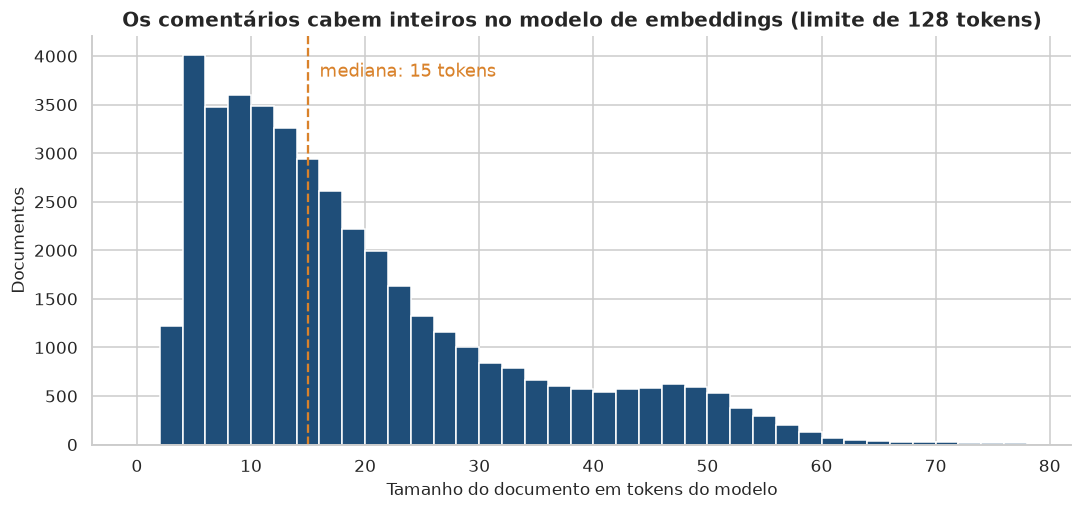

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(docs["n_wordpieces"], bins=range(0, 80, 2), color=BLUE)
med = docs["n_wordpieces"].median()
ax.axvline(med, color=ORANGE, ls="--")
ax.text(med + 1, ax.get_ylim()[1] * 0.9, f"mediana: {med:.0f} tokens", color=ORANGE)
ax.set(title="Os comentários cabem inteiros no modelo de embeddings (limite de 128 tokens)",
       xlabel="Tamanho do documento em tokens do modelo", ylabel="Documentos")
save(fig, "02_tamanho_documentos");

**Decisão D01: um documento por avaliação, sem fragmentação.** O documento mediano tem 54 caracteres e 15 tokens do modelo; o percentil 99 fica em 57 tokens, menos da metade do limite. Só um documento passa de 128 tokens, e o excesso é uma sequência de pontuação (",.,.,.") depois de "excelente. muito bom, recomendo", que o truncamento descarta sem perda. Fragmentar textos desse tamanho só separaria a reclamação do motivo. O chunking que a aula apresenta para documentos longos não se aplica a esta base.

### HT1. Comentários negativos são mais longos

Teste: Mann-Whitney unilateral do número de palavras entre notas 1 e 2 e notas 4 e 5.

In [7]:
por_nota = docs.groupby("review_score")["n_words"].agg(["count", "median", "mean"]).round(1)
neg_w = docs.loc[docs["review_score"] <= 2, "n_words"]
pos_w = docs.loc[docs["review_score"] >= 4, "n_words"]
u, p = stats.mannwhitneyu(neg_w, pos_w, alternative="greater")
r_rb = 2 * u / (len(neg_w) * len(pos_w)) - 1
rho = stats.spearmanr(docs["review_score"], docs["n_words"])
print(f"Mann-Whitney (notas 1-2 > notas 4-5): U = {u:,.0f}, p = {p:.1e}, correlação bisserial de postos = {r_rb:.3f}")
print(f"Spearman nota x palavras: {rho.statistic:.3f}")
por_nota

Mann-Whitney (notas 1-2 > notas 4-5): U = 226,262,621, p = 0.0e+00, correlação bisserial de postos = 0.510
Spearman nota x palavras: -0.381


,count,median,mean
review_score,,,
1,8704,16.0,17.9
2,2133,16.0,17.6
3,3594,13.0,14.8
4,6173,8.0,10.6
5,21489,7.0,8.5


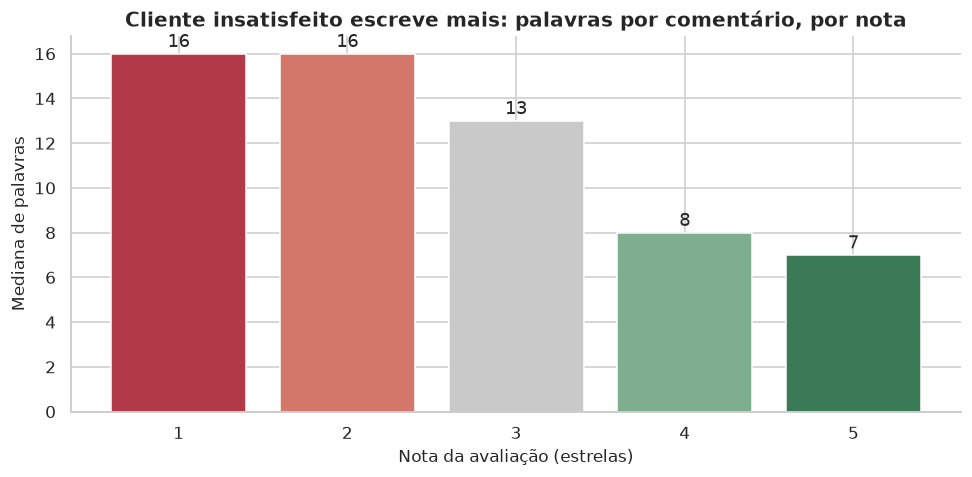

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(por_nota.index.astype(str), por_nota["median"], color=[SCORE_COLORS[n] for n in por_nota.index])
for i, v in enumerate(por_nota["median"]):
    ax.text(i, v + 0.3, f"{v:.0f}", ha="center", fontsize=12)
ax.set(title="Cliente insatisfeito escreve mais: palavras por comentário, por nota",
       xlabel="Nota da avaliação (estrelas)", ylabel="Mediana de palavras")
save(fig, "02_palavras_por_nota");

**HT1 confirmada, com efeito grande (correlação bisserial de postos = 0,51).** A mediana é de 16 palavras nas notas 1 e 2 e de 7 a 8 nas notas 4 e 5 (Spearman entre nota e tamanho = -0,38). O cliente insatisfeito explica o que aconteceu; o satisfeito confirma em poucas palavras.

**Para o RAG:** as evidências de reclamação trazem detalhe (motivo, prazo, pedido de reembolso), enquanto os elogios são curtos e repetitivos. Nas perguntas sobre elogios, a contagem de textos iguais diz mais que os textos em si, o que motiva a deduplicação com contagem.

### Textos repetidos

In [9]:
grupos = docs.drop_duplicates("doc_id")
rep = grupos[grupos["doc_size"] > 1]
dup = pd.Series({
    "textos repetidos (grupos com mais de uma avaliação)": len(rep),
    "avaliações dentro desses grupos": int(rep["doc_size"].sum()),
    "% das avaliações com texto": round(100 * rep["doc_size"].sum() / len(docs), 1),
    "mediana de caracteres dos textos repetidos": rep["n_chars"].median(),
    "maior texto repetido (caracteres)": rep["n_chars"].max(),
})
print(dup.to_string())
top = docs[docs["is_representative"]].nlargest(15, "doc_size")
top.assign(nota_media=top["doc_id"].map(docs.groupby("doc_id")["review_score"].mean().round(2)))[
    ["text_norm", "doc_size", "nota_media"]]

textos repetidos (grupos com mais de uma avaliação)    1026.0
avaliações dentro desses grupos                        8230.0
% das avaliações com texto                               19.6
mediana de caracteres dos textos repetidos               22.0
maior texto repetido (caracteres)                       122.0


,text_norm,doc_size,nota_media
31761,otimo,558,4.83
29174,muito bom,555,4.69
37494,recomendo,420,4.62
574,bom,405,4.18
22909,excelente,266,4.87
17461,super recomendo,153,4.87
11846,otimo produto,138,4.85
34927,ok,130,4.45
27858,otima,120,4.82
16123,boa,118,4.17


In [10]:
por_doc = docs.groupby("doc_id").agg(n=("review_id", "size"), notas=("review_score", "nunique"),
                                     categorias=("main_category", "nunique"))
multi = por_doc[por_doc["n"] > 1]
print(f"grupos repetidos com mais de uma nota: {(multi['notas'] > 1).mean():.0%}")
print(f"grupos repetidos com mais de uma categoria: {(multi['categorias'] > 1).mean():.0%}")

grupos repetidos com mais de uma nota: 51%
grupos repetidos com mais de uma categoria: 93%


**Decisão D04: textos idênticos depois de normalizados viram uma entrada do índice, com a contagem.** 1.026 textos se repetem e cobrem 8.230 avaliações (19,6% das que têm texto). São curtos: mediana de 22 caracteres, e o maior tem 122. "Ótimo" (558 avaliações), "muito bom" (555) e "recomendo" (420) lideram; "não recebi o produto" aparece 107 vezes, com nota média 1,24. Sem a deduplicação, uma pergunta sobre elogios devolveria várias cópias de "ótimo" no top-10.

O grupo, porém, não é homogêneo: 51% dos textos repetidos aparecem com mais de uma nota e 93% com mais de uma categoria. Por isso o índice guarda um texto por grupo, mas o filtro por metadado é aplicado por avaliação: numa pergunta sobre uma categoria, o grupo entra se alguma avaliação dele for da categoria, e a contagem exibida é a das avaliações que passaram no filtro.

Os termos que separam notas baixas e altas vêm na próxima etapa deste notebook.